# Using different distributions in Brightway

This script shows how to add different types of uncertainties to your home-made product system and run a Monte Carlo simulation.

As background it is useful to **read the stats-arrays package documentation** on the parameters to use for uncertainty and for the differnet distributions: https://stats-arrays.readthedocs.io/en/latest/

In [1]:
# Import brightway2.5 packages
import bw2calc as bc
import bw2data as bd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
bd.projects.set_current('testing distributions')

In [3]:
bd.databases

Databases dictionary with 2 object(s):
	interv
	techno

In [4]:
#fresh start
for db in bd.databases.list:
    del bd.databases[db]

bd.databases

Databases dictionary with 0 objects

A short recap, let's create a foreground database and run LCA calculations

First an intervention matrix **B** with one bioshpere exchange only, carbon dioxide emissions

In [5]:
inter_matrix = bd.Database('interv') # Intervention matrix B
inter_matrix.write({('interv', 'Carbon dioxide'): {'name': 'Carbon dioxide', 'unit': 'kg', 'type': 'biosphere'}})

100%|██████████| 1/1 [00:00<00:00, 1356.94it/s]

07:54:50+0100 [info     ] Vacuuming database            


I also create a LCIA method _ad hoc_ for this biosphere exchange, with a charachterisation factor of 1

In [6]:
myLCIAdata = [[('interv', 'Carbon dioxide'), 1.0]]
method_key = ('interv', 'climate impact midpoint', 'nn', 'nn')
my_method = bd.Method(method_key)
my_method.validate(myLCIAdata)
my_method.register()
my_method.write(myLCIAdata)
my_method.load()

[(287115587246530560, 1.0)]

Then a technology matrix **A** with two interconnected activities

In [7]:
techno_matrix = bd.Database('techno')

techno_matrix.write({  # A simplified version, only CO2 as emission
    ('techno', 'Electricity production'): {
        'name': 'Electricity production',
        'unit': 'kWh',
        'location': 'GLO',
        'exchanges': [{
                'input': ('techno', 'Fuel production'),
                'amount': 2,
                'unit': 'kg',
                'type': 'technosphere'
            }, {
                'input': ('interv', 'Carbon dioxide'),
                'amount': 1,
                'unit': 'kg',
                'type': 'biosphere'
            }, {
                'input': ('techno', 'Electricity production'),
                'amount': 10,
                'unit': 'kWh',
                'type': 'production'
            }]
        },
    ('techno', 'Fuel production'): {
        'name': 'Fuel production',
        'unit': 'kg',
        'location': 'GLO',
        'exchanges': [{
                'input': ('interv', 'Carbon dioxide'),
                'amount': 10,
                'unit': 'kg',
                'type': 'biosphere'
            }, {
                'input': ('techno', 'Fuel production'),
                'amount': 100,
                'unit': 'kg',
                'type': 'production'
            }]
    }
    })

100%|██████████| 2/2 [00:00<00:00, 24385.49it/s]

07:54:55+0100 [info     ] Vacuuming database            


Now I run calculation and obtain a nominal score

In [8]:
functional_unit = {techno_matrix.get('Electricity production'): 1000}
lca = bc.LCA(functional_unit, method_key)  # LCA calculations with method
lca.lci()
lca.lcia()

In [9]:
print(lca.score) 

120.0


In [10]:
col_id = techno_matrix.get('Electricity production').id
row_id = techno_matrix.get('Fuel production').id


In [11]:
fuel_value = -lca.technosphere_matrix[lca.activity_dict[row_id], lca.activity_dict[col_id]]
lca.technosphere_matrix[0,0]


10.0

In [12]:
for act in techno_matrix:
    for exc in act.exchanges():
        print(exc)
        print(exc.uncertainty)

Exchange: 10 kg 'Carbon dioxide' (kg, None, None) to 'Fuel production' (kg, GLO, None)>
{}
Exchange: 100 kg 'Fuel production' (kg, GLO, None) to 'Fuel production' (kg, GLO, None)>
{}
Exchange: 2 kg 'Fuel production' (kg, GLO, None) to 'Electricity production' (kWh, GLO, None)>
{}
Exchange: 1 kg 'Carbon dioxide' (kg, None, None) to 'Electricity production' (kWh, GLO, None)>
{}
Exchange: 10 kWh 'Electricity production' (kWh, GLO, None) to 'Electricity production' (kWh, GLO, None)>
{}


# Before starting adding uncertainties, some notes

**Note 1**: uncertainties are always added to **exchanges** (not to activities...)

**Note 2**: production exchanges are assigned no uncertainty, because technosphere and biosphere exchanges are expressed in relation to them (e.g., units of input per unit of ouput) 

**Note 3**: in this tutorial I don't assign uncertainty to carachterisation factors

#  Assigning uncertainty to data: the uniform distribution 

First step is to import the right identifier

In [25]:
from stats_arrays import UniformUncertainty # import brightway identifiers for this distribution

Main assumptions: 
1) The original "amount" value corresponds to the center of the distribution. So we are "centering" the **uniform distribution** on this value. To do this in practice, we specify in brightway that the central value of the **uniform distribution** equals the "amount" value. This is specified by defining the ```loc``` attribute
2) In this case, I am giving all exchanges the **same uncertainty**, in the sense that the width of the distribution is, in proportion, the same for all of them. In this case I am using a value of **10%** and I have arbitrarily decided that all values of the distribution should be in this range. This is specified by defining ```maximum``` and ```minimum```attributes.

It does **not** have to be this way. This is just an example. I am making the assumptions explicit.

I assign uncertainty systematically across the entire database

In [32]:
for act in techno_matrix:
    for exc in act.exchanges():
        if exc['type'] != 'production': # if the exchange is NOT a production type exchange
            #print(exc)
            exc['uncertainty type'] = UniformUncertainty.id # important
            exc['loc'] = exc['amount'] # centering the distribution to the amount value
            exc['maximum'] = exc['amount']*(1+10/100) # 10% upper limit
            exc['minimum'] = exc['amount']*(1-10/100) # 10% lower limit
            exc.save()

Let's give a look

In [33]:
for act in techno_matrix:
    for exc in act.exchanges():
        if exc['type'] != 'production':
            print(exc)
            print(exc.uncertainty)

Exchange: 2 kg 'Fuel production' (kg, GLO, None) to 'Electricity production' (kWh, GLO, None)>
{'uncertainty type': 4, 'loc': 2, 'maximum': 2.2, 'minimum': 1.8}
Exchange: 1 kg 'Carbon dioxide' (kg, None, None) to 'Electricity production' (kWh, GLO, None)>
{'uncertainty type': 4, 'loc': 1, 'maximum': 1.1, 'minimum': 0.9}
Exchange: 10 kg 'Carbon dioxide' (kg, None, None) to 'Fuel production' (kg, GLO, None)>
{'uncertainty type': 4, 'loc': 10, 'maximum': 11.0, 'minimum': 9.0}


Uncertainty information is now stored in the database.

Let's run a simulation, this is how the **uniform** distribution looks like for a single exchange

(array([ 70., 103., 112., 104., 100., 114., 108., 107.,  81., 101.]),
 array([0.90017782, 0.92015213, 0.94012644, 0.96010076, 0.98007507,
        1.00004938, 1.02002369, 1.039998  , 1.05997231, 1.07994662,
        1.09992093]),
 <BarContainer object of 10 artists>)

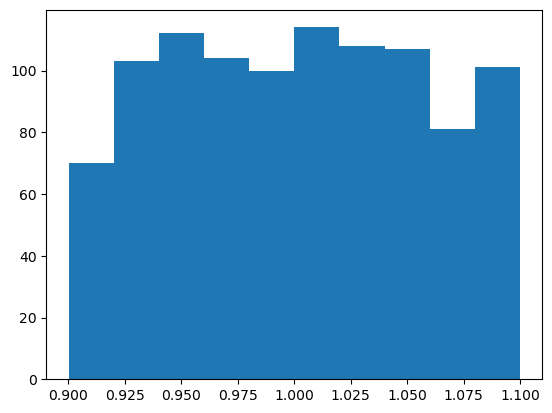

In [34]:
%matplotlib inline
co2_exc = list(techno_matrix.get('Electricity production').exchanges())[1]
plt.hist(co2_exc.random_sample(n=1000))

This is how it looks like for the results of the LCA model.

In [35]:
el = techno_matrix.get('Electricity production')  
mc = bc.LCA(demand={el: 1000}, method=method_key, use_distributions=True)
mc.lci()
mc.lcia()
mc_results = [mc.score for _ in zip(range(500), mc)] # 500 iterations

Text(0.5, 0, 'lca.score')

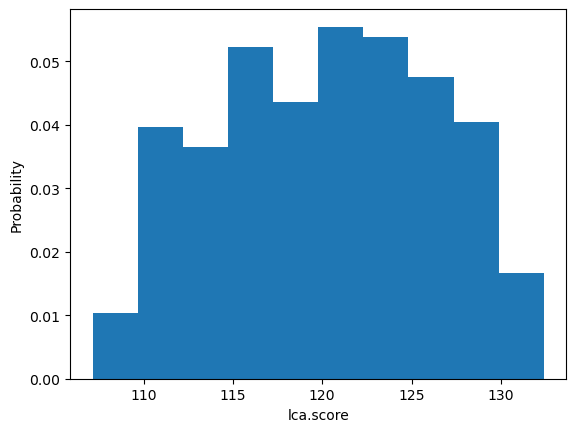

In [36]:
# Look at the MC results, what you see is the sample distribution
plt.hist(mc_results, density=True)  # From matplotlib package. Use bins = int(500/15) to increase number of bars
plt.ylabel("Probability")
plt.xlabel('lca.score')

Interesting effect, it seems that even if each exchange is uniformly distributed, **the distribution of the LCA scores might not be uniform**. This is error propagation!

In [37]:
pd.DataFrame(mc_results).describe()  # the statistics.

,0
count,500.000000
mean,120.208073
std,6.088428
min,107.162324
25%,115.248980
50%,120.437329
75%,125.131769
max,132.399678


#  Similar procedure for the triangular distribution 


Text(0.5, 0, 'lca.score')

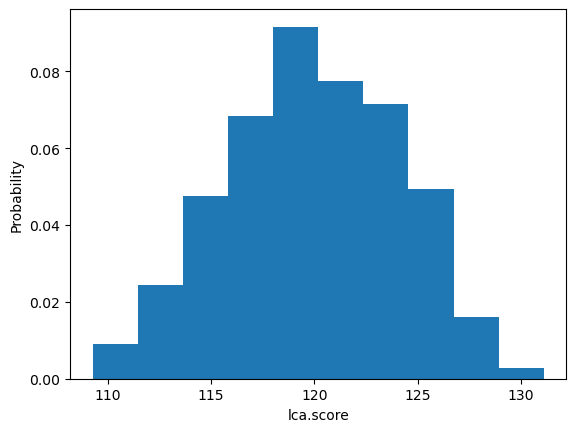

In [38]:
from stats_arrays import TriangularUncertainty # important

for act in techno_matrix:
    for exc in act.exchanges():
        if exc['type'] != 'production': # production type exchanges excluded
            #print(exc)
            exc['uncertainty type'] = TriangularUncertainty.id # use the triangual distr id
            exc['loc'] = exc['amount'] # centering the distribution to the amount value
            exc['maximum'] = exc['amount']*(1+10/100) # 10% upper limit
            exc['minimum'] = exc['amount']*(1-10/100) # 10% lower limit
            exc.save()

el = techno_matrix.get('Electricity production')  
mc = bc.LCA(demand={el: 1000}, method=method_key, use_distributions=True)
mc.lci()
mc.lcia()
mc_results = [mc.score for _ in zip(range(1000), mc)] # 500 iterations

# Look at the MC results, what you see is the sample distribution
plt.hist(mc_results, density=True, bins = int(10))
plt.ylabel("Probability")
plt.xlabel('lca.score')

# Asymmetric, non-centered distributions

Distributions do **not** necessarily need to be centered on the "amount" value and have symmetric bounds.

Check out the setting I am using in the cell below: 
- **loc** is not centered, it is lower than the nominal value.
- **minimim** and **maximum** are not simmmetric (not equally distant) from the nominal value 

In [13]:
from stats_arrays import TriangularUncertainty # important

for act in techno_matrix:
    for exc in act.exchanges():
        if exc['type'] != 'production': # production type exchanges excluded
            #print(exc)
            exc['uncertainty type'] = TriangularUncertainty.id # use the triangual distr id
            exc['loc'] = exc['amount']*0.8 # Not centering the distribution on the amount value, but lower
            exc['maximum'] = exc['amount']*0.8*(1+50/100) # 50% upper limit
            exc['minimum'] = exc['amount']*0.8*(1-5/100) # 5% lower limit
            exc.save()

In [14]:
for act in techno_matrix:
    for exc in act.exchanges():
        if exc['type'] != 'production':
            print(exc)
            print(exc.uncertainty)

Exchange: 2 kg 'Fuel production' (kg, GLO, None) to 'Electricity production' (kWh, GLO, None)>
{'uncertainty type': 5, 'loc': 1.6, 'maximum': 2.4000000000000004, 'minimum': 1.52}
Exchange: 1 kg 'Carbon dioxide' (kg, None, None) to 'Electricity production' (kWh, GLO, None)>
{'uncertainty type': 5, 'loc': 0.8, 'maximum': 1.2000000000000002, 'minimum': 0.76}
Exchange: 10 kg 'Carbon dioxide' (kg, None, None) to 'Fuel production' (kg, GLO, None)>
{'uncertainty type': 5, 'loc': 8.0, 'maximum': 12.0, 'minimum': 7.6}


(array([129., 184., 166., 130., 104.,  98.,  73.,  58.,  40.,  18.]),
 array([0.76533965, 0.80707537, 0.84881108, 0.8905468 , 0.93228252,
        0.97401824, 1.01575396, 1.05748968, 1.0992254 , 1.14096111,
        1.18269683]),
 <BarContainer object of 10 artists>)

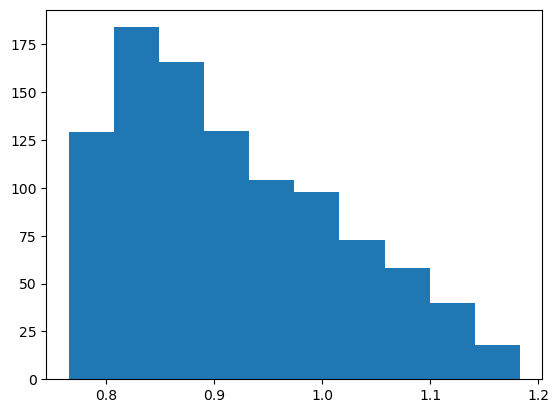

In [15]:
%matplotlib inline
co2_exc = list(techno_matrix.get('Electricity production').exchanges())[1]
plt.hist(co2_exc.random_sample(n=1000))

Text(0.5, 0, 'lca.score')

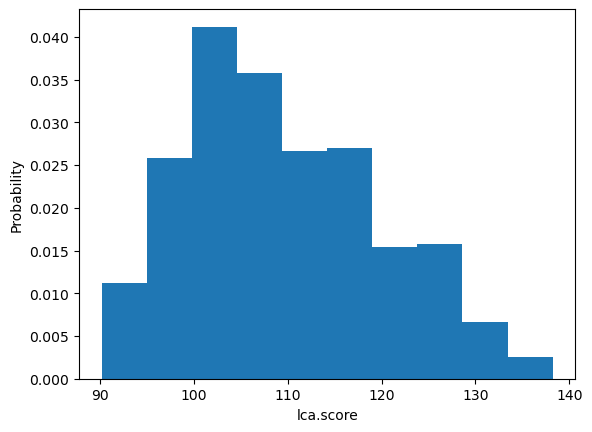

In [16]:
el = techno_matrix.get('Electricity production')  
mc = bc.LCA(demand={el: 1000}, method=method_key, use_distributions=True)
mc.lci()
mc.lcia()
mc_results = [mc.score for _ in zip(range(500), mc)] # 500 iterations

# Look at the MC results, what you see is the sample distribution
plt.hist(mc_results, density=True) 
plt.ylabel("Probability")
plt.xlabel('lca.score')

In [17]:
pd.DataFrame(mc_results).describe()

,0
count,500.000000
mean,109.619111
std,10.284678
min,90.161922
25%,101.771654
50%,108.057085
75%,116.980324
max,138.223714


#  Assigning uncertainty to data: the normal distribution

Let me clean up a bit first, I remove the information about maximum and minimum bounds for the moment (can always be added later).

Here you can also see how you can **remove** uncertainty...in case you want to do it.

In [21]:
for act in techno_matrix:
    for exc in act.exchanges():
        exc.pop('maximum',None) # removes the maximum key and value, skips if this is not found
        exc.pop('minimum',None) # same with minimum
        #if 'minimum' in exc: # alternatively
        #    del exc['minimum']
        exc.save()

In [22]:
# a check
for act in techno_matrix:
    for exc in act.exchanges():
        if exc['type'] != 'production':
            print(exc.uncertainty)

{'uncertainty type': 3, 'loc': 10, 'scale': 0.3333333333333333}
{'uncertainty type': 3, 'loc': 2, 'scale': 0.06666666666666667}
{'uncertainty type': 3, 'loc': 1, 'scale': 0.03333333333333333}


Now I can assign a **normal** distribution to each exchange. 

In [23]:
from stats_arrays import NormalUncertainty # import brightway identifiers for this distribution

Main assumptions: 
1) the original "amount" value corresponds to the center of the distribution. So we are "centering" the **normal distribution** on this value. To do this in practice, we specify in brightway that the mean (so, the central value) of the **normal distribution** equals the "amount" value. This is specified by defining the ```loc``` attribute
2) Again in this case I am giving all exchanges the same uncertainty, in the sense that the width of the distirbution is, in proportion, the same for all of them. In this case I am using a value of 10% and I have arbitrarily decided that 99% of all values of the distirbution should be in this range. This corresponds to a distance of **three standard deviations** from the mean value and is specified by defining ```scale``` attribute.

Again, it does **not** need to be necessarily this way, this is just an example. I am making the assumptions explicit.

In [24]:
for act in techno_matrix:
    for exc in act.exchanges():
        if exc['type'] != 'production': # production type exchanges excluded
            #print(exc)
            exc['uncertainty type'] = NormalUncertainty.id
            exc['loc'] = exc['amount'] # centering the distribution on the amount value
            exc['scale'] = exc['amount']* (10/100) / 3 # three standard deviations within the 10% bound
            exc.save()

In [25]:
for act in techno_matrix:
    for exc in act.exchanges():
        if exc['type'] != 'production':
            print(exc)
            print(exc.uncertainty) # notice the "type" as changed to 3.

Exchange: 2 kg 'Fuel production' (kg, GLO, None) to 'Electricity production' (kWh, GLO, None)>
{'uncertainty type': 3, 'loc': 2, 'scale': 0.06666666666666667}
Exchange: 1 kg 'Carbon dioxide' (kg, None, None) to 'Electricity production' (kWh, GLO, None)>
{'uncertainty type': 3, 'loc': 1, 'scale': 0.03333333333333333}
Exchange: 10 kg 'Carbon dioxide' (kg, None, None) to 'Fuel production' (kg, GLO, None)>
{'uncertainty type': 3, 'loc': 10, 'scale': 0.3333333333333333}


In [26]:
el = techno_matrix.get('Electricity production')  
mc = bc.LCA(demand={el: 1000}, method=method_key, use_distributions=True)
mc.lci()
mc.lcia()
mc_results = [mc.score for _ in zip(range(500), mc)] # 500 iterations

Text(0.5, 0, 'lca.score')

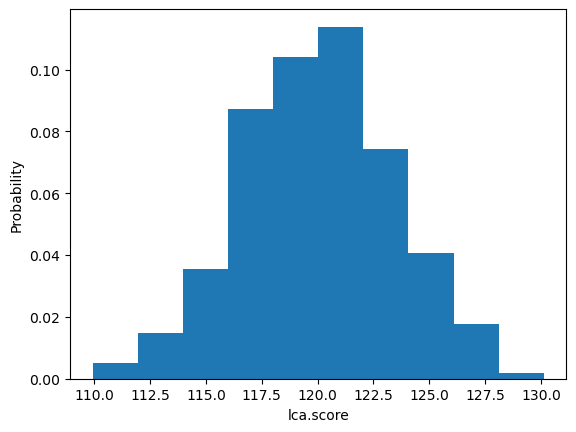

In [27]:
# Look at the MC results, what you see is the sample distribution
plt.hist(mc_results, density=True)  # From matplotlib package. Use bins = int(500/15) to increase number of bars
plt.ylabel("Probability")
plt.xlabel('lca.score')

The **50% percentile**, which is the center of the distribution and in this case also the sample mean, **is close to the nominal value**.

In [28]:
pd.DataFrame(mc_results).describe()  

,0
count,500.000000
mean,120.020325
std,3.425474
min,109.928412
25%,117.741949
50%,120.029083
75%,122.281417
max,130.126494


Why do I write "close" and not "equal to"? Because this is a stochastic simulation with 500 iterations. If we had 1000 iterations it would be closer. With one million iterations it would be very, very close. One billion iterations, probably almost identical. If we had infinite iterations it would be the same (in theory).

# Normal distribution with a fixed lower bound

A nice feature is that one can set a lower bound, this can be useful to e.g. avoid negative results when using a normal distribution with large standard deviation

In [30]:
for act in techno_matrix:
    for exc in act.exchanges():
        if exc['type'] != 'production': # production type exchanges excluded
            #print(exc)
            exc['uncertainty type'] = NormalUncertainty.id
            exc['loc'] = exc['amount'] # centering the distribution to the amount value
            exc['scale'] = exc['amount']* 1/3 # a much larger standard deviations of 1/3 the mean value, this coudl likely result in negative values on the left side of the mean
            exc['minimum'] =  exc['amount']* 0.5 # the minimum value should be 50% of the amount
            exc.save()

(array([100., 132., 208., 203., 154., 105.,  56.,  29.,  10.,   3.]),
 array([0.50029518, 0.6585566 , 0.81681802, 0.97507944, 1.13334087,
        1.29160229, 1.44986371, 1.60812514, 1.76638656, 1.92464798,
        2.0829094 ]),
 <BarContainer object of 10 artists>)

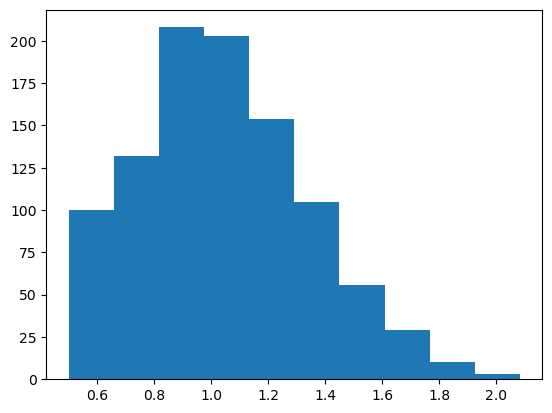

In [31]:
%matplotlib inline
co2_exc = list(techno_matrix.get('Electricity production').exchanges())[1]
plt.hist(co2_exc.random_sample(n=1000))

Text(0.5, 0, 'lca.score')

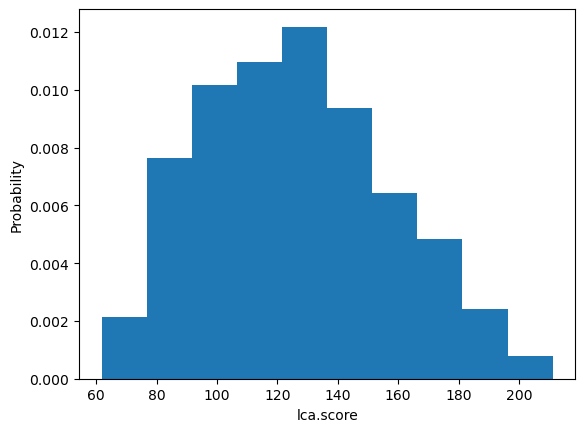

In [32]:
el = techno_matrix.get('Electricity production')  
mc = bc.LCA(demand={el: 1000}, method=method_key, use_distributions=True)
mc.lci()
mc.lcia()
mc_results = [mc.score for _ in zip(range(500), mc)] # 500 iterations

# Look at the MC results, what you see is the sample distribution
plt.hist(mc_results, density=True)  # From matplotlib package. Use bins = int(500/15) to increase number of bars
plt.ylabel("Probability")
plt.xlabel('lca.score')

#  Fitting lognormal uncertainty

I now assign a **lognormal distribution** to all exchanges in the product system

Main assumptions: 
1) the original "amount" value corresponds to the center of the distribution. So we are "centering" the **lognormal distribution** on this value. To do this in practice, we specify in brightway that **the mean** (so, the central value) **of the underlying normal distribution** equals the "amount" value. To do this, we need to calculate the logarithm of the amount value doing ```np.log(exc['amount'])```
2) Again in this case I give all exchanges the same uncertainty, in the sense that the width of the distribution is, in proportion, the same for all of them. In this case I am using a value of 1.1. What does it mean? Roughly, in terms of lognormal distribution it meas that 66% of the values will be in the interval of [amount / 1.1 ; amount *1.1].  We'll see more of this later. Consistently with what we do for the location, we take the logarithm of the gsd to represent the scale. This is **the standard deviation of the underlying normal distribution**.

In [33]:
from stats_arrays import LognormalUncertainty # import brightway identifiers for this distribution

In [34]:
# First clean up
for act in techno_matrix:
    for exc in act.exchanges():
        exc.pop('maximum',None) # removes the maximum key and value
        exc.pop('minimum',None)# same for minimum
        exc.save()

Loop through all exchanges that are not production, assign lognormal distirbution.

In [35]:
for act in techno_matrix:
    for exc in act.exchanges():
        if exc['type'] != 'production':
            exc['uncertainty type'] = LognormalUncertainty.id
            exc['loc'] = np.log(exc['amount']) # centering the distribution
            exc['scale'] = np.log(2.1) # defining the breath of the distribution
            exc.save()

Check uncertainty is now stored

In [36]:
for act in techno_matrix:
    for exc in act.exchanges():
        if exc['type'] != 'production':
            print(exc)
            print(exc.uncertainty)

Exchange: 10 kg 'Carbon dioxide' (kg, None, None) to 'Fuel production' (kg, GLO, None)>
{'uncertainty type': 2, 'loc': 2.302585092994046, 'scale': 0.7419373447293773}
Exchange: 2 kg 'Fuel production' (kg, GLO, None) to 'Electricity production' (kWh, GLO, None)>
{'uncertainty type': 2, 'loc': 0.6931471805599453, 'scale': 0.7419373447293773}
Exchange: 1 kg 'Carbon dioxide' (kg, None, None) to 'Electricity production' (kWh, GLO, None)>
{'uncertainty type': 2, 'loc': 0.0, 'scale': 0.7419373447293773}


Now run the MC simulation

In [37]:
el = techno_matrix.get('Electricity production')  
mc = bc.LCA(demand={el: 1000}, method=method_key, use_distributions=True)
mc.lci()
mc.lcia()
mc_results = [mc.score for _ in zip(range(500), mc)] # 500 iterations

Text(0.5, 0, 'lca.score')

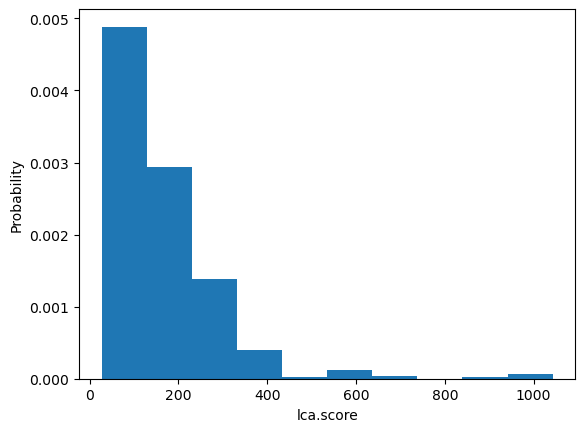

In [38]:
# Look at the MC results, what you see is the sample distribution
plt.hist(mc_results, density=True)  # From matplotlib package. Use bins = int(500/15) to increase number of bars
plt.ylabel("Probability")
plt.xlabel('lca.score')

Note that now the mean and median are **higher** than the nominal value.

In [39]:
print(np.mean(mc_results)) # from numpy package
print(np.median(mc_results)) # from numpy package
print(lca.score) # the nominal value

166.56106736161183
130.25631175900028
120.0


In [40]:
pd.DataFrame(mc_results).describe()  # useful descriptive stats from pandas package

,0
count,500.000000
mean,166.561067
std,127.757276
min,27.082254
25%,85.762430
50%,130.256312
75%,214.026158
max,1042.636179


# Note on proportional uncertainty

I mentioned that the range of exchanges **in proportion** is the same: let's see more of this.
I take an exchange and calculate an upper and lower bound using the geometric standard deviation. This is a multiplicative relationship. The same value of gsd can be used for two values of exchanges to obtain a range.

In [43]:
fuel_exc = list(el.exchanges())[0]
print('Fuel amount is:' , fuel_exc['amount'] , 
      '\nlower bound is:', fuel_exc['amount']/1.1/1.1/1.1, 
      '\nupper bound is:', fuel_exc['amount']*1.1*1.1*1.1)

co2_exc = list(el.exchanges())[1]
print('CO2 amount is:' , co2_exc['amount'] , 
      '\nlower bound is:', co2_exc['amount']/1.1/1.1/1.1, 
      '\nupper bound is:', co2_exc['amount']*1.1*1.1*1.1)

Fuel amount is: 2 
lower bound is: 1.5026296018031553 
upper bound is: 2.662000000000001
CO2 amount is: 1 
lower bound is: 0.7513148009015777 
upper bound is: 1.3310000000000004


(array([528., 308.,  96.,  31.,  23.,   6.,   3.,   3.,   1.,   1.]),
 array([ 0.08668892,  1.08669939,  2.08670987,  3.08672034,  4.08673081,
         5.08674129,  6.08675176,  7.08676223,  8.0867727 ,  9.08678318,
        10.08679365]),
 <BarContainer object of 10 artists>)

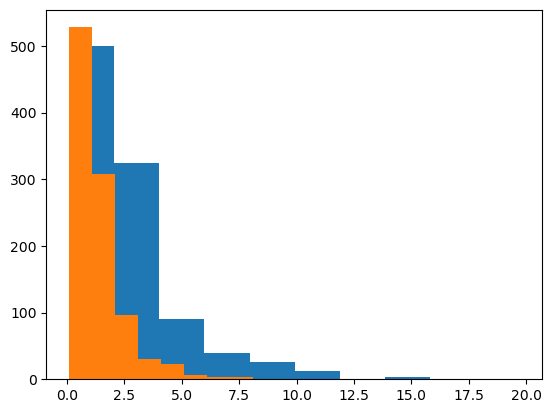

In [44]:
# if you want to see this
%matplotlib inline
plt.hist(fuel_exc.random_sample(n=1000))
plt.hist(co2_exc.random_sample(n=1000))

# Using the Pedigree matrix

One can use pedigree scores to give uncertainty.

I am using in the example the pedigree factors found [here](https://github.com/brightway-lca/pedigree_matrix/blob/main/pedigree_matrix/pm.p). The code says these are used by ecoinvent, but I don't know where they are documented. 

The equations for calculating the uncertainty value and its meaning are provided in _Ciroth, A., Muller, S., Weidema, B. et al. Empirically based uncertainty factors for the pedigree matrix in ecoinvent. Int J Life Cycle Assess 21, 1338–1348 (2016). https://doi.org/10.1007/s11367-013-0670-5_

For an excell explaination, see here: https://zenodo.org/records/10842720 the Calculator of uncertainty using pedigree matrix (.xlsx file)

In [85]:
#We first get the list of pedigree factors. 

pedigree_factors_v1 = [[1.00, 1.05, 1.10, 1.20, 1.50], #"reliability"
[1.00, 1.02, 1.05, 1.10, 1.20], #"completeness"
[1.00, 1.02, 1.05, 1.10, 1.20],#"temporal correlation"
[1.00, 1.02, 1.05, 1.10, 1.20], #"geographical correlation"
[1.00, 1.02, 1.05, 1.10, 1.20], #"further technological correlation"
[1.00, 1.02, 1.05, 1.10, 1.20]] #"sample size"

scores = [1, 1, 5, 5, 1, 1] # assume these are the scores you give to an exchange

factors = [] # we now find the factors matching those scores

for score in scores:
    i = scores.index(score)
    factor = pedigree_factors_v1[i][score-1]
    factors.append(factor)

factors

[1.0, 1.0, 1.2, 1.2, 1.0, 1.0]

We can now calculate an uncertainty value from the pedigree factors.

Specifically, what the pedigree return is an uncertainty estimate, that is supposed ot be intended as the **variance** of a lognormal distribution. 

There is not a strong (or at all) scientific bais for this, this is an asusmption due to convenience.

Probably becuase the lognormal distribution avoids the problem of negative values.

Overall, the pedigrree matrix can be defined as a semi-quantitative, expert-based uncertainty estimation method.

It has been criticized a lot. it remains a pragmatic alternative for uncertainty estimation at database scale.

In [96]:
# step by step
logs = np.log(factors); print("logarithm of the factors:", logs)
logs2 = logs**2; print("square the values:", logs2)
s_logs2 = np.sum(logs2); print("sum of squared logs:", s_logs2)
sqrt_s_logs2 = np.sqrt(s_logs2); print("square root of sum of squared logs:", sqrt_s_logs2)
unc = np.exp(sqrt_s_logs2); print("uncertainty, assumed to be the variance of a lognormal distribution:", unc)
gsd = unc**0.5; print("geometric standard deviation (square root of uncertainty):", gsd)
scale = np.log(gsd); print("scale (logarithm of geometric standard deviation), to be used in brightway:", scale)


logarithm of the factors: [0.         0.         0.18232156 0.18232156 0.         0.        ]
square the values: [0.         0.         0.03324115 0.03324115 0.         0.        ]
sum of squared logs: 0.06648230014354242
square root of sum of squared logs: 0.2578416183309871
uncertainty, assumed to be the variance of a lognormal distribution: 1.2941338353151037
geometric standard deviation (square root of uncertainty): 1.1376000331026295
scale (logarithm of geometric standard deviation), to be used in brightway: 0.12892080916549356


This can be assigned to an exchange. note: the lognormal uncertainty distribution has to be used in this case.

In [94]:
fuel_exc = list(el.exchanges())[0]
fuel_exc['uncertainty type'] = LognormalUncertainty.id
fuel_exc['loc'] = np.log(fuel_exc['amount']) # centering the distribution
fuel_exc['scale'] = scale # defining the breath of the distribution
fuel_exc.save()

print(fuel_exc.uncertainty)

{'uncertainty type': 2, 'loc': 0.6931471805599453, 'scale': 0.12892080916549356}


# Biggest problem with Monte Carlo simulation 

In [118]:
el = techno_matrix.get('Electricity production')  
mc = bc.LCA(demand={el: 50}, method=method_key, use_distributions=True)
mc.lci()
mc.lcia()

Here I do something interesting, **I take out the inventory values at each iteration**, not only the scores. So I can look at the relation between inputs and outputs.

In [119]:
mc_results = [{'fuel use': -mc.technosphere_matrix[1,0], # this is explained below
               'CO2 emis': mc.biosphere_matrix[0,0], # check below at the end of notebook
               'Score': mc.score} for _ in zip(range(500), mc)] # 500 iterations

In [120]:
pd.DataFrame(mc_results).describe() # we look at the distributions

,fuel use,CO2 emis,Score
count,500.000000,500.000000,500.000000
mean,2.017251,1.238190,7.470797
std,0.268325,0.989573,5.098651
min,1.388326,0.105098,1.125343
25%,1.833991,0.580842,4.099675
50%,2.004769,0.934063,6.235720
75%,2.178680,1.520955,9.206295
max,3.158690,8.350957,44.630361


We look at the **correlation matrix** between the amount of fuel used and the CO2 emissions. There is **no correlation**. This because each exchange is sampled independently. 

This is **a serious problem**, because we break mass-balances and relationships between inputs and outputs.

In [121]:
pd.DataFrame(mc_results).corr()

,fuel use,CO2 emis,Score
fuel use,1.000000,0.008614,0.041685
CO2 emis,0.008614,1.000000,0.980746
Score,0.041685,0.980746,1.000000


We can see the same in a visual way by plotting one distribution versus the other. 
If there was a direct proportional relation, one should see a straight line. Do you see it? I don't.

Text(0, 0.5, 'kg CO2-eq')

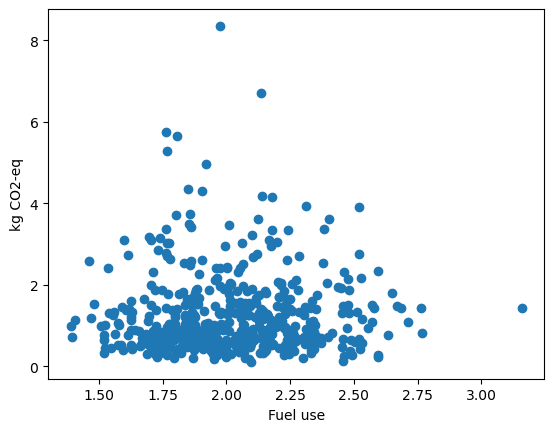

In [122]:
# plot one against the other to see if there is any trend
plt.plot(pd.DataFrame(mc_results)['fuel use'], pd.DataFrame(mc_results)['CO2 emis'], 'o')
plt.xlabel('Fuel use')
plt.ylabel('kg CO2-eq')

Bonus, how did I know how to extract specific input values? Remember that brightway uses a system of coordinates to ientify excahnges in the matrices

In [125]:
# Find the coordinates of each exchange

col_id = techno_matrix.get('Electricity production').id # the activiy electricity production
row_id = techno_matrix.get('Fuel production').id # the product of fuel production
print(row_id, col_id)

row = mc.activity_dict[row_id]
col = mc.activity_dict[col_id]
print(row,col)

-mc.technosphere_matrix[row,col] # the minus sign is because inputs in the tech matrix are negative by convention!!!

287115606972342273 287115606972342272
1 0


2.192531184383495

In [123]:
col_id = techno_matrix.get('Electricity production').id # the activiy electricity production
row_id = inter_matrix.get('Carbon dioxide').id # the emission of CO2 (in the biospehere matrix!)
print(row_id, col_id)

col = mc.activity_dict[col_id]
row = mc.biosphere_dict[row_id]
print(row,col)

print(mc.biosphere_matrix[row,col])

287115587246530560 287115606972342272
0 0
0.970427445244731
